# Week 2 · Multimodal data and measurement
## A defensible measure and a readable dataset v0.1
STATS 201 · November 2 and 4, 2026 · Luyao (Sunshine) Zhang

**Purpose.** Turn your Week 1 question into a measurement that another researcher can inspect and reuse. You may change your topic completely. The six blocks connect source selection, critique, a measured change, documentation, release, and revision.

**You are becoming…** an empirical thinker who checks what an indicator represents, an interdisciplinary contributor who makes a computational rule understandable, and a responsible collaborator who respects authority, attribution, and reuse conditions (LO2–6).

**Start.** In Colab choose **File → Save a copy in Drive**. Use a CPU. Run the supplied example, then edit the configuration and your own reasoning. All results display below the cells. No results ZIP or mandatory download is required. Share your Drive copy with instructor **Viewer** access and check that the instructor can open it. A Drive copy does not update GitHub.

**AI permissions.** Initial individual judgments, the ten-minute individual Ed reflection, and the handwritten exit are **Human-Only**. During coding/release work, **AI-Assisted** help may explain code, debug, suggest tests, translate, or critique your own draft. You own the argument and interpretation. Record the model, date, purpose, consequential prompts, accepted/rejected outputs, revisions, and verification. Do not put credentials in prompts or notebook cells.

**One evolving record.** Theory gives your initial measurement. Practice supplies a source passport and a checked figure. Research challenges the measure with published evidence. Innovation uses peer review to revise the data and your proposal. By **Sunday November 8, 23:00 China Standard Time**, link an actual readable dataset v0.1 under the instructor-confirmed course Hugging Face organization in your two-page individual reflection, with one figure. A local preview or release plan alone does not complete this milestone. **Weekly reflections are individual submissions. Canvas tools randomly generate the in-class groups separately each day.** These temporary groups support discussion and review; the publication organizations are separate from assessment groups.

The supplied examples demonstrate methods. They do not count as your independent proposal, critique, or contribution.

## 0 · Setup
The install cell uses compatible major-version ranges. Later cells print the installed versions. pandas inspects tables; Matplotlib makes the one required figure; Hugging Face tools publish and reload data; mlcroissant checks machine-readable metadata. No paid model or GPU is needed.

In [1]:
# RUN & OBSERVE · Colab / Jupyter setup
import sys, subprocess, importlib.util
required = {"pandas":"pandas>=2,<4", "matplotlib":"matplotlib>=3.8,<4",
            "openpyxl":"openpyxl>=3.1,<4", "pyarrow":"pyarrow>=17,<27",
            "huggingface_hub":"huggingface_hub>=0.34,<3", "datasets":"datasets>=4,<6",
            "mlcroissant":"mlcroissant>=1,<2"}
missing = [spec for module,spec in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pathlib import Path
from datetime import datetime, timezone
import io, json, hashlib, urllib.request, re, copy, platform
from importlib.metadata import version
print({m:version(m) for m in required})
print("CPU workflow ready. Publication is off until you explicitly enable it.")

{'pandas': '2.2.3', 'matplotlib': '3.10.8', 'openpyxl': '3.1.5', 'pyarrow': '26.0.0', 'huggingface_hub': '2.4.0', 'datasets': '5.1.0', 'mlcroissant': '1.1.1'}
CPU workflow ready. Publication is off until you explicitly enable it.


## 1 · Choose support and a source
Choose **A Guided**, **B Curated menu**, or **C Independent**. All routes use the same criteria, and you may switch without penalty. If a viable source is still missing after 15 minutes, begin with one of the starters.

Choose a **2025–2026 Scientific Data or NeurIPS dataset-track paper with an actual released dataset**. Read the paper and its release separately. The [module guide](https://github.com/sunshineluyao/ml4ss/tree/main/modules/01-measurement) contains ten options across arts/media, social science, and environment/Earth science, including robotics and quantum circuits.

### Human-Only · Think–Pair–Share
Think individually, compare your reason with a partner, then write your own correction. This is a structured peer-feedback application, not evidence that pairing automatically improves learning [P1, P4].

**Empirical purpose:** A Measurement · B Explanation · C Prediction · D Causal inference · E Optimization · F Frontier method (also state the underlying aim).

For the default task choose **A**: the density of harmonic annotations is an observable measure. Whether it captures musical complexity needs separate validity evidence.

**Before coding:** complete page 1 of the before/after handout. State your question, required datasets, unit, initial measurement rule, expected output, and one peer challenge.

In [2]:
# STUDENT INPUT · filled teaching defaults, not a student answer
# Change STARTER first. Its topic/filter/measure defaults follow automatically.
ROUTE = "A"                         # A, B, C; support choice never changes the criteria
STARTER = 'corelli'
TOPIC_OVERRIDE = "USE_STARTER_DEFAULT"
KEYWORDS_OVERRIDE = "USE_STARTER_DEFAULT" # literal words separated by |; ALL keeps every row
MAX_ROWS = 300                       # deterministic first matching rows; 10..5000
USE_NETWORK = True                  # False uses a clearly labelled small dated excerpt
EMPIRICAL_PURPOSE = "A Measurement"
MY_INITIAL_JUDGMENT = "USE_STARTER_DEFAULT"
MY_PEER_CHALLENGE = "TEACHING EXAMPLE: does this observed quantity capture the intended concept and scope?"
AUTHOR_NAME = "Teaching example"     # replace with your chosen scholarly attribution before publishing
CODE_REPOSITORY = "https://github.com/sunshineluyao/ml4ss"
# Set the real instructor-confirmed organization when it is announced. No invented namespace.
COURSE_HF_ORG = "INSTRUCTOR_TO_ANNOUNCE"
DATASET_NAME = "week2-measurement-example"  # use your own unique project slug before publication
LIVE_PUBLISH = False                 # only enable after your human review and org access
RELEASE_VERSION = "v0.1.0"           # use a NEW version for a later revision
print("Your route:",ROUTE,"| source:",STARTER,"| live publication:",LIVE_PUBLISH)

Your route: A | source: corelli | live publication: False


In [3]:
# READ & LEARN · source passports and dated offline excerpts
PRESETS = {'corelli': {'title': 'Distant Listening Corpus Corelli metadata', 'paper': 'https://doi.org/10.1038/s41597-025-04976-z', 'source': 'https://github.com/DCMLab/corelli', 'download': 'https://raw.githubusercontent.com/DCMLab/corelli/main/metadata.tsv', 'format': 'tsv', 'license': 'cc-by-nc-sa-4.0', 'license_url': 'https://creativecommons.org/licenses/by-nc-sa/4.0/', 'unit': 'notated movement', 'time': 'Composition years in source fields; one static metadata record per movement, not repeated audio sampling.', 'geography': 'Corelli corpus; no population sampling frame.', 'topic': 'Annotation density in Corelli movements', 'keywords': 'sonata', 'text_col': 'workTitle', 'id_col': 'piece', 'scope': '149 source rows inspected November 1 2026', 'meaning': 'Harmonic annotation density per notated quarter-note beat', 'limits': 'This selected composer corpus and its annotation conventions do not establish general musical complexity or audience experience.', 'bias': 'Composer, repertoire and annotation-convention selection; excerpts are not random samples of all music.', 'sensitive': 'The released selected fields describe musical works, counts and composition years; personal annotator fields are deliberately excluded.', 'impact': 'Reusable annotation-density audit; mislabelling it as aesthetic quality can misrepresent cultural value.', 'credit': 'Hentschel, Rammos, Neuwirth & Rohrmeier (2025), Scientific Data 12, 685. Corelli source attribution: Hentschel, Moss, Neuwirth & Rohrmeier (2021), ISMIR 262–269, doi:10.5281/zenodo.5624417.', 'columns': ['piece', 'workTitle', 'movementTitle', 'length_qb', 'n_onsets', 'label_count', 'composed_start', 'composed_end'], 'excerpt': [{'piece': 'op01n01a', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Grave', 'length_qb': 56.0, 'n_onsets': 280, 'label_count': 64, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n01b', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 152.0, 'n_onsets': 721, 'label_count': 141, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n01c', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Adagio', 'length_qb': 111.0, 'n_onsets': 304, 'label_count': 97, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n01d', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 294.0, 'n_onsets': 878, 'label_count': 147, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n02a', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Grave', 'length_qb': 76.0, 'n_onsets': 317, 'label_count': 76, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n02b', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Vivace', 'length_qb': 144.0, 'n_onsets': 500, 'label_count': 121, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n02c', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Adagio', 'length_qb': 87.0, 'n_onsets': 210, 'label_count': 67, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n02d', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 175.5, 'n_onsets': 815, 'label_count': 174, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n03a', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Grave', 'length_qb': 68.0, 'n_onsets': 259, 'label_count': 66, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n03b', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 216.0, 'n_onsets': 1154, 'label_count': 223, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n03c', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Adagio', 'length_qb': 210.0, 'n_onsets': 182, 'label_count': 71, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n03d', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 291.0, 'n_onsets': 881, 'label_count': 177, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n04a', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Vivace', 'length_qb': 76.0, 'n_onsets': 409, 'label_count': 52, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n04b', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Adagio', 'length_qb': 48.0, 'n_onsets': 198, 'label_count': 26, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n04c', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 112.0, 'n_onsets': 701, 'label_count': 117, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n04d', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Presto', 'length_qb': 156.0, 'n_onsets': 545, 'label_count': 115, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n05a', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Grave', 'length_qb': 252.0, 'n_onsets': 342, 'label_count': 90, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n05b', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 156.0, 'n_onsets': 753, 'label_count': 149, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n05c', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Adagio - Allegro', 'length_qb': 146.0, 'n_onsets': 308, 'label_count': 59, 'composed_start': 1681, 'composed_end': 1681}, {'piece': 'op01n05d', 'workTitle': 'Sonata da chiesa', 'movementTitle': 'Allegro', 'length_qb': 177.0, 'n_onsets': 605, 'label_count': 117, 'composed_start': 1681, 'composed_end': 1681}], 'excerpt_date': '2026-11-01', 'inspected_file_sha256': '02b5ac77630b4a47c885ef281a607046ba197e004efc4ddee70bd0ffd0c777ae'}, 'finance': {'title': 'Chinese Development Finance climate annotations', 'paper': 'https://doi.org/10.1038/s41597-026-06605-9', 'source': 'https://doi.org/10.6084/m9.figshare.30015124', 'download': 'https://ndownloader.figshare.com/files/57516988', 'format': 'xlsx', 'license': 'cc0-1.0', 'license_url': 'https://creativecommons.org/publicdomain/zero/1.0/', 'unit': 'development-finance project', 'time': 'Commitment years 2000–2021; project records are events, not a regular time series.', 'geography': 'Recipients in the released source, subject to its coverage.', 'topic': 'Counting projects and funding for solar and wind finance', 'keywords': 'solar|wind', 'text_col': 'Title', 'id_col': 'ID', 'scope': '20,985 source rows inspected November 1 2026', 'meaning': 'Reported amount in constant 2021 USD per selected project; missing amount remains missing', 'limits': 'A keyword subset is selective. Recorded funding and labels do not establish realized disbursement, climate impact or causal effects.', 'bias': 'Reporting, source coverage and title-word selection may exclude relevant projects or include false positives.', 'sensitive': 'The selected released fields concern projects and recipients; review titles for unexpected identifiers before publishing your own subset.', 'impact': 'Funding-coverage audit can support transparent reuse. Missing amounts or keyword omissions can distort resource comparisons.', 'credit': 'Qi, Tang, Zhang, Wang & Qian (2026), Scientific Data 13, 277. Retain the AidData provenance and original project identifiers.', 'columns': ['ID', 'AidData_Record_ID', 'Commitment_Year', 'Recipient', 'Recipient_Region', 'Title', 'Amount_Constant_USD_2021', 'rio_marker'], 'excerpt': [{'ID': 174, 'AidData_Record_ID': 93766, 'Commitment_Year': 2021, 'Recipient': 'Burkina Faso', 'Recipient_Region': 'Africa', 'Title': 'Chinese Government provides CFA 3.4 billion grant for 4MW Bazega Solar Power Plant Construction Project', 'Amount_Constant_USD_2021': 6131318.41, 'rio_marker': '2,2,1'}, {'ID': 798, 'AidData_Record_ID': 93258, 'Commitment_Year': 2021, 'Recipient': 'Namibia', 'Recipient_Region': 'Africa', 'Title': 'Chinese Embassy donates N$ 1 million worth of COVID-19 equipment to 7 schools in Windhoek, Namibia ', 'Amount_Constant_USD_2021': 67659.0, 'rio_marker': '0,0,0'}, {'ID': 841, 'AidData_Record_ID': 97571, 'Commitment_Year': 2021, 'Recipient': 'Nigeria', 'Recipient_Region': 'Africa', 'Title': 'PowerChina-Kunming Engineering Cooperation Limited donates Solar Equipment to Usman Dan Fodio University Communities in Nigeria in December 2021', 'Amount_Constant_USD_2021': None, 'rio_marker': '2,2,0'}, {'ID': 876, 'AidData_Record_ID': 96173, 'Commitment_Year': 2021, 'Recipient': 'Pakistan', 'Recipient_Region': 'Asia', 'Title': 'China provides RMB 21 million grant for Solar-Powered Lightning Equipment Project', 'Amount_Constant_USD_2021': 3255813.95, 'rio_marker': '2,2,1'}, {'ID': 934, 'AidData_Record_ID': 96035, 'Commitment_Year': 2021, 'Recipient': 'Philippines', 'Recipient_Region': 'Asia', 'Title': 'ICBC participates in PHP 1.6 billion syndicated loan for Phases 3A and 3B of the Bataan Solar Project', 'Amount_Constant_USD_2021': 16237061.09, 'rio_marker': '2,2,0'}, {'ID': 1201, 'AidData_Record_ID': 96567, 'Commitment_Year': 2021, 'Recipient': 'Tonga', 'Recipient_Region': 'Oceania', 'Title': 'Government of China pledges 87 million RMB to wind farm in Tongatapu', 'Amount_Constant_USD_2021': 13488372.09, 'rio_marker': '2,2,1'}, {'ID': 1227, 'AidData_Record_ID': 96123, 'Commitment_Year': 2021, 'Recipient': 'Turkey', 'Recipient_Region': 'Europe', 'Title': 'ICBC and China Construction Bank contribute to $523 million syndicated loan for 1.35 GW Kalyon Karapınar Solar Power Plant Project', 'Amount_Constant_USD_2021': 174333333.0, 'rio_marker': '2,2,1'}, {'ID': 1289, 'AidData_Record_ID': 96465, 'Commitment_Year': 2021, 'Recipient': 'Viet Nam', 'Recipient_Region': 'Asia', 'Title': 'Bank of China contributes to $81 million syndicated loan for Lotus Wind Power Project in 2021', 'Amount_Constant_USD_2021': 40500000.0, 'rio_marker': '2,2,1'}, {'ID': 1514, 'AidData_Record_ID': 91639, 'Commitment_Year': 2020, 'Recipient': 'Botswana', 'Recipient_Region': 'Africa', 'Title': 'Chinese Government donates solar-powered street lights worth BWP 7.5 million to Botswana in December 2020', 'Amount_Constant_USD_2021': 731552.62, 'rio_marker': '2,2,1'}, {'ID': 1698, 'AidData_Record_ID': 95243, 'Commitment_Year': 2020, 'Recipient': 'Chile', 'Recipient_Region': 'America', 'Title': 'China Co-Financing Fund for Latin America and the Caribbean provides $36 million loan for 151 MW Calama wind farm (Linked to Project ID#86526)', 'Amount_Constant_USD_2021': 40206132.09, 'rio_marker': '2,2,1'}, {'ID': 1719, 'AidData_Record_ID': 91430, 'Commitment_Year': 2020, 'Recipient': 'Colombia', 'Recipient_Region': 'America', 'Title': 'Chinese Embassy in Colombia donates 6 solar panels to Puerto Alegria, Colombia', 'Amount_Constant_USD_2021': None, 'rio_marker': '2,2,0'}, {'ID': 2117, 'AidData_Record_ID': 88650, 'Commitment_Year': 2020, 'Recipient': 'Kazakhstan', 'Recipient_Region': 'Asia', 'Title': 'ICBC provides $13.3 million loan for Zhanatas Wind Power Project', 'Amount_Constant_USD_2021': 14853932.13, 'rio_marker': '2,2,0'}, {'ID': 2216, 'AidData_Record_ID': 55896, 'Commitment_Year': 2020, 'Recipient': 'Lesotho', 'Recipient_Region': 'Africa', 'Title': 'China Eximbank provides RMB 481.5 million government concessional loan for Phase 1 of Ramarothole 70MW Solar Generation Project', 'Amount_Constant_USD_2021': 77935799.51, 'rio_marker': '2,2,0'}, {'ID': 2375, 'AidData_Record_ID': 85018, 'Commitment_Year': 2020, 'Recipient': 'Mexico', 'Recipient_Region': 'America', 'Title': '[China Co-Financing Fund] IDB Invest administers $4.6 million loan from CHC for Xoxocotla Solar PV Plant', 'Amount_Constant_USD_2021': 5137450.21, 'rio_marker': '2,2,1'}, {'ID': 2557, 'AidData_Record_ID': 93201, 'Commitment_Year': 2020, 'Recipient': 'Namibia', 'Recipient_Region': 'Africa', 'Title': 'Nanjing donates 30,000 face masks to the city of Windhoek in June 2020', 'Amount_Constant_USD_2021': 10051.53, 'rio_marker': '0,0,0'}, {'ID': 2558, 'AidData_Record_ID': 93202, 'Commitment_Year': 2020, 'Recipient': 'Namibia', 'Recipient_Region': 'Africa', 'Title': 'Shanghai donates 20,000 masks to Windhoek, Namibia in May 2020', 'Amount_Constant_USD_2021': 29484.5, 'rio_marker': '0,0,0'}, {'ID': 2676, 'AidData_Record_ID': 95305, 'Commitment_Year': 2020, 'Recipient': 'Pakistan', 'Recipient_Region': 'Asia', 'Title': "China's Ministry of Ecology and Environment donate 4,000 sets of solar photovoltaic systems and LED lights to Balochistan Provincial Government", 'Amount_Constant_USD_2021': None, 'rio_marker': '2,2,1'}, {'ID': 3200, 'AidData_Record_ID': 92621, 'Commitment_Year': 2020, 'Recipient': 'Turkey', 'Recipient_Region': 'Europe', 'Title': 'ICBC provides $37 million loan for 72MW Kiyikoy Wind Farm Expansion Project', 'Amount_Constant_USD_2021': 41322969.09, 'rio_marker': '2,2,1'}, {'ID': 3312, 'AidData_Record_ID': 88700, 'Commitment_Year': 2020, 'Recipient': 'Viet Nam', 'Recipient_Region': 'Asia', 'Title': 'ICBC contributes to $38.39 million syndicated loan for 50MW Thinh Long Phú Yên Solar Farm Project (Linked to Project ID#88903)', 'Amount_Constant_USD_2021': 28583581.31, 'rio_marker': '2,2,1'}, {'ID': 3323, 'AidData_Record_ID': 95979, 'Commitment_Year': 2020, 'Recipient': 'Viet Nam', 'Recipient_Region': 'Asia', 'Title': 'China Eximbank provides loan — via EPCF arrangement — for 330MW Phu My Solar Power Plant Project', 'Amount_Constant_USD_2021': 253750951.13, 'rio_marker': '2,2,1'}], 'excerpt_date': '2026-11-01', 'inspected_file_sha256': '7dbab2971c78350188c499730ad9075142feaa9fcc0e127da6b74e588ab16225'}, 'heritage': {'title': 'Glo-CoH coastal World Heritage attributes', 'paper': 'https://doi.org/10.1038/s41597-026-07758-3', 'source': 'https://doi.org/10.25375/uct.28547267', 'download': 'https://ndownloader.figshare.com/files/59458244', 'format': 'xlsx', 'license': 'cc-by-4.0', 'license_url': 'https://creativecommons.org/licenses/by/4.0/', 'unit': 'heritage-site component', 'time': 'Static release snapshot; no periodic time series. Retrieve the source record for release dates.', 'geography': 'Global selected coastal World Heritage components.', 'topic': 'Area and coverage of coastal heritage components', 'keywords': 'ALL', 'text_col': 'Name of Site', 'id_col': 'ID', 'scope': '1,250 component rows inspected November 1 2026; components differ from properties', 'meaning': 'Component area in square kilometres converted from source hectares', 'limits': 'The attribute table alone does not measure damage, future loss, community value or all world heritage. Components can share a property.', 'bias': 'UNESCO designation and coastal-selection coverage; counts weight components equally rather than by area or community value.', 'sensitive': 'Selected fields describe designated sites. Public coordinates and site naming can still raise community and conservation concerns; this release omits geometry.', 'impact': 'Transparent area-unit harmonization supports reuse. Treating components as independent properties or exposure as observed loss can mislead.', 'credit': 'Bescoby, Clarke, Okolie, Nicholls, Simpson, Vafeidis & Vousdoukas (2026), Scientific Data 13, 1082.', 'columns': ['ID', 'Name of Site', 'Designated Name', 'Country', 'ISO Code', 'UNESCO Designated Sub-Region', 'Area (ha)'], 'excerpt': [{'ID': 1, 'Name of Site': 'Butrint - Vrina plain', 'Designated Name': 'Butrint', 'Country': 'Albania', 'ISO Code': 'ALB', 'UNESCO Designated Sub-Region': 'Europe and North America', 'Area (ha)': 282.129}, {'ID': 2, 'Name of Site': 'Butrint - Diaporit', 'Designated Name': 'Butrint', 'Country': 'Albania', 'ISO Code': 'ALB', 'UNESCO Designated Sub-Region': 'Europe and North America', 'Area (ha)': 44.728}, {'ID': 3, 'Name of Site': 'Butrint', 'Designated Name': 'Butrint', 'Country': 'Albania', 'ISO Code': 'ALB', 'UNESCO Designated Sub-Region': 'Europe and North America', 'Area (ha)': 69.891}, {'ID': 4, 'Name of Site': 'Kasbah of Algiers', 'Designated Name': 'Kasbah of Algiers', 'Country': 'Algeria', 'ISO Code': 'DZA', 'UNESCO Designated Sub-Region': 'Arab States', 'Area (ha)': 74.075}, {'ID': 5, 'Name of Site': 'Tipasa: Parc archaéologique ouest', 'Designated Name': 'Tipasa', 'Country': 'Algeria', 'ISO Code': 'DZA', 'UNESCO Designated Sub-Region': 'Arab States', 'Area (ha)': 32.698}, {'ID': 6, 'Name of Site': 'Tipasa: Parc archaéologique est', 'Designated Name': 'Tipasa', 'Country': 'Algeria', 'ISO Code': 'DZA', 'UNESCO Designated Sub-Region': 'Arab States', 'Area (ha)': 16.325}, {'ID': 7, 'Name of Site': 'Antigua Naval Dockyard and Related Archaeological Sites', 'Designated Name': 'Antigua Naval Dockyard and Related Archaeological Sites', 'Country': 'Antigua and Barbuda', 'ISO Code': 'ATG', 'UNESCO Designated Sub-Region': 'Latin America and the Carribean', 'Area (ha)': 274.139}, {'ID': 8, 'Name of Site': 'Maison du docteur Curutchet', 'Designated Name': 'The Architectural Work of Le Corbusier, an Outstanding Contribution to the Modern Movement', 'Country': 'Argentina', 'ISO Code': 'ARG', 'UNESCO Designated Sub-Region': 'Latin America and the Carribean', 'Area (ha)': 0.021}, {'ID': 9, 'Name of Site': 'ESMA Museum and Site of Memory – Former Clandestine Center of Detention, Torture and Extermination', 'Designated Name': 'ESMA Museum and Site of Memory – Former Clandestine Center of Detention, Torture and Extermination', 'Country': 'Argentina', 'ISO Code': 'ARG', 'UNESCO Designated Sub-Region': 'Latin America and the Carribean', 'Area (ha)': 1.055}, {'ID': 10, 'Name of Site': 'Península Valdés', 'Designated Name': 'Península Valdés', 'Country': 'Argentina', 'ISO Code': 'ARG', 'UNESCO Designated Sub-Region': 'Latin America and the Carribean', 'Area (ha)': 384606.984}, {'ID': 11, 'Name of Site': 'Shark Bay, Western Australia', 'Designated Name': 'Shark Bay, Western Australia', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 2200064.114}, {'ID': 12, 'Name of Site': 'Lord Howe Island Group', 'Designated Name': 'Lord Howe Island Group', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 453.22}, {'ID': 13, 'Name of Site': "K'gari (Fraser Island)", 'Designated Name': "K'gari (Fraser Island)", 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 181307.508}, {'ID': 14, 'Name of Site': 'Heard and McDonald Islands', 'Designated Name': 'Heard and McDonald Islands', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 645362.238}, {'ID': 15, 'Name of Site': 'Kakadu National Park', 'Designated Name': 'Kakadu National Park', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 1909003.99}, {'ID': 16, 'Name of Site': 'Port Arthur Historic Site (“Port Arthur”)', 'Designated Name': 'Australian Convict Sites', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 113.931}, {'ID': 17, 'Name of Site': 'Darlington Probation Station (“Darlington”)', 'Designated Name': 'Australian Convict Sites', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 374.383}, {'ID': 18, 'Name of Site': 'Component around Mission Beach', 'Designated Name': 'Wet Tropics of Queensland', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 11092.152}, {'ID': 19, 'Name of Site': 'Fremantle Prison', 'Designated Name': 'Australian Convict Sites', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 5.809}, {'ID': 20, 'Name of Site': 'Hyde Park Barracks', 'Designated Name': 'Australian Convict Sites', 'Country': 'Australia', 'ISO Code': 'AUS', 'UNESCO Designated Sub-Region': 'Asia and Pacific', 'Area (ha)': 0.521}], 'excerpt_date': '2026-11-01', 'inspected_file_sha256': '7e4b5ebf6243a8917f3be792c6aa50df97b93d0d4fc8c8b7654163b16f5de89c'}}
assert ROUTE in ["A","B","C"] and STARTER in [*PRESETS,"custom"]
assert 10 <= MAX_ROWS <= 5000
if STARTER != "custom":
    passport = copy.deepcopy(PRESETS[STARTER])
    print({k:v for k,v in passport.items() if k not in ["excerpt","columns"]})
else:
    print("Custom route: define CUSTOM in the next cell after reading its evidence requirements.")

{'title': 'Distant Listening Corpus Corelli metadata', 'paper': 'https://doi.org/10.1038/s41597-025-04976-z', 'source': 'https://github.com/DCMLab/corelli', 'download': 'https://raw.githubusercontent.com/DCMLab/corelli/main/metadata.tsv', 'format': 'tsv', 'license': 'cc-by-nc-sa-4.0', 'license_url': 'https://creativecommons.org/licenses/by-nc-sa/4.0/', 'unit': 'notated movement', 'time': 'Composition years in source fields; one static metadata record per movement, not repeated audio sampling.', 'geography': 'Corelli corpus; no population sampling frame.', 'topic': 'Annotation density in Corelli movements', 'keywords': 'sonata', 'text_col': 'workTitle', 'id_col': 'piece', 'scope': '149 source rows inspected November 1 2026', 'meaning': 'Harmonic annotation density per notated quarter-note beat', 'limits': 'This selected composer corpus and its annotation conventions do not establish general musical complexity or audience experience.', 'bias': 'Composer, repertoire and annotation-convent

### Custom route adapter
Routes B/C may use the same pipeline for a permitted tabular derivative, an annotation table, or a media manifest with stable item IDs. Keep protected media outside a public release when rights do not permit redistribution. Do not convert raw media into an unexplained number.

In the following cell, set `CUSTOM` to a dictionary after completing the source passport. Required keys: title, paper, source, download, format (`csv`, `tsv`, `xlsx`), license (Hub identifier), license_url, unit, time, geography, topic, keywords, text_col, id_col, columns, meaning, limits, bias, sensitive, impact, credit. Add measure_col, measure_unit, and a **callable measure** receiving the source DataFrame and returning a numeric Series. Choose a reviewed, clearly permitted source. The automatic release gate requires human confirmation of publication eligibility and rights.

For custom data this generic loader does not implement every archive or modality. Inspect the selected source with its documented loader, build a small permitted record table, then adapt the loader here. Use a starter if access or parsing prevents a Week 2 release.

In [4]:
# STUDENT INPUT · only required when STARTER == "custom"
CUSTOM = None
if STARTER == "custom":
    needed = {"title","paper","source","download","format","license","license_url","unit","time","geography","topic","keywords","text_col","id_col","columns","meaning","limits","bias","sensitive","impact","credit","measure_col","measure_unit","measure"}
    if not isinstance(CUSTOM,dict) or needed - set(CUSTOM):
        raise ValueError("Complete the custom source passport/measurement adapter, or select a working starter.")
    assert callable(CUSTOM["measure"])
    passport = copy.deepcopy(CUSTOM)
TOPIC = passport["topic"] if TOPIC_OVERRIDE == "USE_STARTER_DEFAULT" else TOPIC_OVERRIDE
KEYWORDS = passport["keywords"] if KEYWORDS_OVERRIDE == "USE_STARTER_DEFAULT" else KEYWORDS_OVERRIDE
if MY_INITIAL_JUDGMENT == "USE_STARTER_DEFAULT":
    MY_INITIAL_JUDGMENT = {"corelli":"TEACHING EXAMPLE: annotation counts may confound duration and musical complexity.","finance":"TEACHING EXAMPLE: known funding amounts may cover fewer projects than a project count suggests.","heritage":"TEACHING EXAMPLE: equal component counts can conceal different component areas.","custom":"TEACHING EXAMPLE: the source indicator needs a construct and coverage check."}[STARTER]
print("Question:",TOPIC,"\nFilter:",KEYWORDS,"\nInitial reasoning:",MY_INITIAL_JUDGMENT)

Question: Annotation density in Corelli movements 
Filter: sonata 
Initial reasoning: TEACHING EXAMPLE: annotation counts may confound duration and musical complexity.


## 2 · Inspect the actual data and critique one point
**Paired source audit:** the author identifies a row, field, or documentation passage; a partner checks its interpretation against the paper/data; then switch roles. Record your own correction [P4].

Critique with seven checks: (1) construct and rule, (2) observation unit, (3) sampling and omissions, (4) quality and validity, (5) time/space/modal alignment, (6) rights and affected communities, (7) the smallest useful and reproducible improvement. For each selected issue use **source evidence → proposed change → validation → research/reuse value**. Adding a dataset can help, but more rows, a file conversion, or reuploading alone does not establish originality.

In [5]:
# RUN & OBSERVE · no silent synthetic substitution
source_bytes = None
if USE_NETWORK:
    try:
        with urllib.request.urlopen(passport["download"],timeout=40) as response:
            source_bytes = response.read()
        reader = pd.read_excel if passport["format"] == "xlsx" else pd.read_csv
        raw = reader(io.BytesIO(source_bytes), **({} if passport["format"]=="xlsx" else {"sep":"\t" if passport["format"]=="tsv" else ","}))
        source_mode = "LIVE SOURCE FILE"
    except Exception as exc:
        print("Network/source access failed:",type(exc).__name__)
        if STARTER == "custom": raise
        raw = pd.DataFrame(passport["excerpt"])
        source_mode = "DATED 20-ROW EXCERPT, 2026-11-01; NOT THE FULL SOURCE"
else:
    if STARTER == "custom": raise ValueError("Custom sources need an explicitly supplied loader/fixture.")
    raw = pd.DataFrame(passport["excerpt"])
    source_mode = "DATED 20-ROW EXCERPT, 2026-11-01; NOT THE FULL SOURCE"
source_sha = hashlib.sha256(source_bytes).hexdigest() if source_bytes else passport["inspected_file_sha256"]
downloaded_rows = len(raw)
assert set(passport["columns"]).issubset(raw.columns), "Source schema changed; inspect it before proceeding."
raw = raw[passport["columns"]].copy()
display(Markdown(f"**{source_mode}** · {downloaded_rows:,} loaded rows · unit: {passport['unit']}"))
display(raw.head(5))
display(pd.DataFrame({"dtype":raw.dtypes.astype(str),"missing":raw.isna().sum(),"missing_share":raw.isna().mean()}))
print("Frequency/time:",passport["time"],"\nScope:",passport["geography"])
print("Duplicate primary IDs:",raw[passport["id_col"]].duplicated().sum())
print("Source SHA-256:",source_sha)
RUN_SIGNATURE = {"starter":STARTER,"keywords":KEYWORDS,"max_rows":MAX_ROWS,"source_mode":source_mode,"source_sha256":source_sha}
CONFIG_SIGNATURE={"route":ROUTE,"starter":STARTER,"topic_override":TOPIC_OVERRIDE,"keywords_override":KEYWORDS_OVERRIDE,"max_rows":MAX_ROWS,"use_network":USE_NETWORK}
print("Run settings:",RUN_SIGNATURE)

Frequency/time: Composition years in source fields; one static metadata record per movement, not repeated audio sampling. 
Scope: Corelli corpus; no population sampling frame.
Duplicate primary IDs: 0
Source SHA-256: 02b5ac77630b4a47c885ef281a607046ba197e004efc4ddee70bd0ffd0c777ae
Run settings: {'starter': 'corelli', 'keywords': 'sonata', 'max_rows': 300, 'source_mode': 'LIVE SOURCE FILE', 'source_sha256': '02b5ac77630b4a47c885ef281a607046ba197e004efc4ddee70bd0ffd0c777ae'}


**LIVE SOURCE FILE** · 149 loaded rows · unit: notated movement

,piece,workTitle,movementTitle,length_qb,n_onsets,label_count,composed_start,composed_end
0,op01n01a,Sonata da chiesa,Grave,56.0,280,64,1681,1681
1,op01n01b,Sonata da chiesa,Allegro,152.0,721,141,1681,1681
2,op01n01c,Sonata da chiesa,Adagio,111.0,304,97,1681,1681
3,op01n01d,Sonata da chiesa,Allegro,294.0,878,147,1681,1681
4,op01n02a,Sonata da chiesa,Grave,76.0,317,76,1681,1681


,dtype,missing,missing_share
piece,object,0,0.0
workTitle,object,0,0.0
movementTitle,object,0,0.0
length_qb,float64,0,0.0
n_onsets,int64,0,0.0
label_count,int64,0,0.0
composed_start,int64,0,0.0
composed_end,int64,0,0.0


## 3 · Make and validate one measured change
**Purpose: measurement.** A rule maps observations to a quantity, with a named unit and limits. In general, mᵢ = g(xᵢ). A representation becomes evidence for your construct only after a relevant validity check.

| Starter | Intuition and rule | Pseudocode | Source |
|---|---|---|---|
| Corelli | Compare annotations per notated beat: mᵢ = label_countᵢ / length_qbᵢ | check denominator > 0; divide; verify row | Hentschel et al. 2025, Scientific Data |
| Finance | Distinguish missing funding from zero: mᵢ = reported constant-2021-USD amount | parse amount; preserve missing; compare count and funding coverage | Qi et al. 2026, Scientific Data |
| Glo-CoH | Harmonize hectares into km²: mᵢ = area_haᵢ / 100 | preserve component ID; convert; verify inverse | Bescoby et al. 2026, Scientific Data |

These default changes teach valid units and documentation. **Unit conversion alone is not an original scientific contribution.** Add your own evidenced label audit, coverage analysis, harmonized source join, or a validated measurement/reuse improvement. Record why it matters. A small well-justified derivative can be a Week 2 prototype without claiming publication-level novelty.

In [6]:
# RUN & OBSERVE · a deterministic keyword subset and explicit measurement
if str(KEYWORDS).upper() == "ALL":
    matching = raw.copy()
else:
    terms = [t.strip() for t in str(KEYWORDS).split("|") if t.strip()]
    assert terms, "Use words separated by |, or ALL."
    text = raw[passport["text_col"]].fillna("").astype(str)
    mask = np.logical_or.reduce([text.str.contains(t,case=False,regex=False).to_numpy() for t in terms])
    matching = raw.loc[mask].copy()
if matching.empty:
    raise ValueError("No matching records. Inspect titles; broaden keywords or use ALL. Zero matches do not prove absence in the world.")
release = matching.head(MAX_ROWS).copy()
if STARTER == "corelli":
    denom = pd.to_numeric(release["length_qb"],errors="coerce")
    release["annotation_density"] = pd.to_numeric(release["label_count"],errors="coerce").div(denom.where(denom>0))
    measure_col, measure_unit = "annotation_density", "harmonic labels per notated quarter-note beat"
elif STARTER == "finance":
    release["reported_amount_2021_usd"] = pd.to_numeric(release["Amount_Constant_USD_2021"],errors="coerce")
    measure_col, measure_unit = "reported_amount_2021_usd", "constant 2021 USD"
elif STARTER == "heritage":
    release["area_km2"] = pd.to_numeric(release["Area (ha)"],errors="coerce")/100
    measure_col, measure_unit = "area_km2", "square kilometres per component"
else:
    measure_col,measure_unit = passport["measure_col"],passport["measure_unit"]
    release[measure_col] = CUSTOM["measure"](release)
release["evidence_type"] = "derived_from_released_source"
assert not release[passport["id_col"]].isna().any()
assert release[passport["id_col"]].is_unique, "Resolve duplicate IDs with evidence; do not silently delete records."
assert release[measure_col].notna().any(), "The derived measure is entirely missing."
quality = {"loaded_rows":downloaded_rows,"matching_rows":len(matching),"released_rows":len(release),"measure_missing":int(release[measure_col].isna().sum()),"duplicate_ids":int(release[passport["id_col"]].duplicated().sum()),"selection":"first MAX_ROWS matching source rows, not random or representative","source_mode":source_mode}
display(pd.DataFrame([quality])); display(release.head(5))
print("Measure:",measure_col,"|",measure_unit)
print("Checked example:", release[[passport["id_col"],measure_col]].iloc[0].to_dict())

Measure: annotation_density | harmonic labels per notated quarter-note beat
Checked example: {'piece': 'op01n01a', 'annotation_density': 1.1428571428571428}


,loaded_rows,matching_rows,released_rows,measure_missing,duplicate_ids,selection,source_mode
0,149,149,149,0,0,"first MAX_ROWS matching source rows, not rando...",LIVE SOURCE FILE


,piece,workTitle,movementTitle,length_qb,n_onsets,label_count,composed_start,composed_end,annotation_density,evidence_type
0,op01n01a,Sonata da chiesa,Grave,56.0,280,64,1681,1681,1.142857,derived_from_released_source
1,op01n01b,Sonata da chiesa,Allegro,152.0,721,141,1681,1681,0.927632,derived_from_released_source
2,op01n01c,Sonata da chiesa,Adagio,111.0,304,97,1681,1681,0.873874,derived_from_released_source
3,op01n01d,Sonata da chiesa,Allegro,294.0,878,147,1681,1681,0.500000,derived_from_released_source
4,op01n02a,Sonata da chiesa,Grave,76.0,317,76,1681,1681,1.000000,derived_from_released_source


Caption starter: 149 notated movement records, LIVE SOURCE FILE; harmonic labels per notated quarter-note beat. This selected composer corpus and its annotation conventions do not establish general musical complexity or audience experience.
Answer: the plotted measure describes this selected release. Construct validity needs the documented human/reference check below.


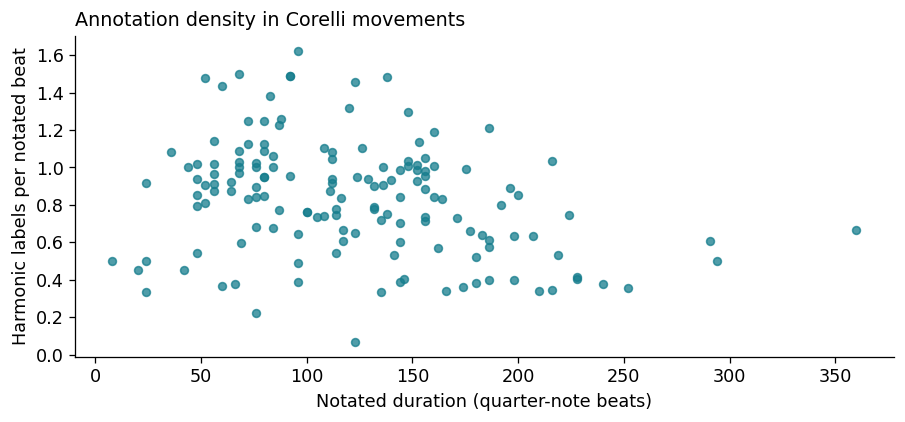

In [7]:
# RUN & OBSERVE · Figure 1, the only required figure
# Keep zeros and missing values explicit. No causal or predictive estimate is computed.
plt.rcParams.update({"figure.dpi":115,"font.size":11})
fig, ax = plt.subplots(figsize=(8,3.8))
if STARTER == "corelli":
    ax.scatter(release["length_qb"],release[measure_col],s=24,color="#167D8D",alpha=.75)
    ax.set(xlabel="Notated duration (quarter-note beats)",ylabel="Harmonic labels per notated beat")
elif STARTER == "finance":
    by=release.groupby("Commitment_Year")[measure_col].agg(["size","count","sum"])
    by.loc[by["count"]==0,"sum"]=np.nan
    ax.plot(by.index,by["sum"]/1e6,"o-",color="#167D8D")
    ax.set(xlabel="Commitment year",ylabel="Known reported funding (million constant 2021 USD)")
    print("Missing amount records:",quality["measure_missing"],"of",len(release),". Missing is not zero.")
else:
    ax.hist(release[measure_col].dropna(),bins=min(15,max(3,len(release)//10)),color="#167D8D")
    ax.set(xlabel=measure_unit,ylabel="Released records")
ax.set_title(TOPIC,loc="left",fontsize=12)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); display(fig); plt.close(fig)
print(f"Caption starter: {len(release)} {passport['unit']} records, {source_mode}; {measure_unit}. {passport['limits']}")
print("Answer: the plotted measure describes this selected release. Construct validity needs the documented human/reference check below.")

In [8]:
# HUMAN CHECK · replace all TEACHING EXAMPLE text with your own checked evidence
EXAMPLE_RESPONSES = {
 "corelli":["raw counts confound duration and density.","add labels per notated beat, preserving counts.","divide the first row by hand and inspect source annotation conventions.","an inspectable annotation-density audit; complexity needs expert reference labels.","review a small set under a common annotation codebook."],
 "finance":["project counts and funding totals use different denominators; missing amounts can distort coverage.","preserve missing amounts and add a typed constant-2021-USD measure.","compare a source row and report the count with known amounts.","a reusable funding-coverage audit; title keywords need manual relevance checks.","audit keyword matches and omissions against project descriptions."],
 "heritage":["component counts and property counts differ, and areas vary.","preserve component IDs and harmonize hectares into square kilometres.","verify inverse conversion for source rows and check component/property definitions.","a reusable area-unit and coverage audit; conversion alone does not establish novelty.","compare component, property and area coverage with checked grouping keys."],
 "custom":["state one source-specific limitation.","describe the actual transformation.","state performed numerical and construct checks.","explain measured scientific or reuse value.","name a feasible next validation."]}
MY_CRITIQUE, MY_CHANGE, MY_VALIDATION, MY_SCIENTIFIC_VALUE, MY_NEXT_TEST = ["TEACHING EXAMPLE: "+t for t in EXAMPLE_RESPONSES[STARTER]]
# A required traceable numerical check for the selected default. A person must also inspect source meaning.
r=release.iloc[0]
if STARTER=="corelli": expected=float(r["label_count"])/float(r["length_qb"])
elif STARTER=="finance": expected=float(r["Amount_Constant_USD_2021"])
elif STARTER=="heritage": expected=float(r["Area (ha)"])/100
else: expected=float(CUSTOM["measure"](release.iloc[[0]]).iloc[0])
actual=float(r[measure_col])
assert np.isclose(actual,expected,equal_nan=True)
print("Arithmetic check:",{"expected":expected,"actual":actual,"pass":True})
print("Your evidence → change → validation → value:")
for t in [MY_CRITIQUE,MY_CHANGE,MY_VALIDATION,MY_SCIENTIFIC_VALUE]: print(t)
print("A passing arithmetic check verifies implementation, not the construct.")

Arithmetic check: {'expected': 1.1428571428571428, 'actual': 1.1428571428571428, 'pass': True}
Your evidence → change → validation → value:
TEACHING EXAMPLE: raw counts confound duration and density.
TEACHING EXAMPLE: add labels per notated beat, preserving counts.
TEACHING EXAMPLE: divide the first row by hand and inspect source annotation conventions.
TEACHING EXAMPLE: an inspectable annotation-density audit; complexity needs expert reference labels.
A passing arithmetic check verifies implementation, not the construct.


## Research bridge · Two Nature readings
**Reciprocal claim checking:** one reader links a claim to a measurement and source; a partner checks whether its scope follows, then switch [P4].

1. Bettencourt & Marchio (2025), *Infrastructure deficits and informal settlements in sub-Saharan Africa*, Nature 645, 399–406. https://doi.org/10.1038/s41586-025-09465-2 . Inspect the operational access measure and the external/community comparisons. A building or street proxy needs a defensible link to deprivation.
2. Sticher et al. (2026), *Advancing conflict research and response through satellite-derived data*, Nature 657, 891–899. https://doi.org/10.1038/s41586-026-11004-6 . Inspect how text reports and satellite-visible damage reflect different data-generating mechanisms. Output improvement/enrichment differs from inferring a latent phenomenon through fusion.

**Guiding question:** will adding a modality improve your construct, or just add another imperfect proxy? **Answer:** specify which omission it addresses, align units/time/space, and test the combined rule against relevant reference evidence. Neither reading is an optimization or causal-identification demonstration in this class.

Ed Research reply: closest source passage/figure; one measurement limitation; one revision and its check. Use your existing Ed record, without adding a second required figure.

## 4 · Build the human and machine-readable release
**FAIR**: Findable, Accessible, Interoperable, Reusable. Authorized access can still be FAIR. **CARE**: Collective Benefit, Authority to Control, Responsibility, Ethics, grounded in Indigenous data governance. Applying its questions to other communities does not remove their authority or confer certification.

The Dataset Card explains meaning. The data dictionary names fields, units and missingness. **Croissant 1.1** describes files and record fields. Eight RAI/provenance entries describe limitations, bias, sensitive information, use, effects, synthetic data, origins and transformations. NeurIPS 2026 **Evaluations & Datasets** requires core plus minimal RAI for dataset contributions; this teaching exercise is not a conference submission.

The notebook generates a **local preview** before any publication. Its local Croissant URL is a file URI. Publication rebuilds the saved metadata using your actual organization URL. You must check the online validator linked in the official hosting guide and record the real outcome. Platform-generated Croissant core can omit RAI.

If you design a benchmark, additionally state target/task, split unit, leakage checks, baselines, metrics/uncertainty and a reproducible evaluation protocol. This measurement tutorial does not train or benchmark models.

In [9]:
# STUDENT INPUT · keep unperformed reviews false; no dummy completion
HUMAN_CHECKS = {
 "eligible_published_source": False,  # personally checked 2025–26 paper and real dataset
 "rights_and_authority_checked": False,
 "selected_rows_reviewed_for_sensitive_data": False,
 "measurement_and_contribution_checked": False,
 "card_and_rai_reviewed": False,
 "peer_review_and_revision_done": False,
 "official_validator_passed": False,
}
PEER_COMMENT = "TEACHING EXAMPLE: separate annotation density from claims about complexity."
AUTHOR_REVISION = "TEACHING EXAMPLE: narrow the descriptor to annotation density and document the next expert check."
PEER_REVIEW_URL = "Record a real review link before publishing"
VALIDATOR_RECEIPT = "Record actual validator result, date and version before publishing"
AI_USE_STATEMENT = "Record no use, or tool/model, date, purpose, significant prompts, accepted/rejected output, revisions and verification."
print(pd.Series(HUMAN_CHECKS,name="Human checks"))

eligible_published_source                    False
rights_and_authority_checked                 False
selected_rows_reviewed_for_sensitive_data    False
measurement_and_contribution_checked         False
card_and_rai_reviewed                        False
peer_review_and_revision_done                False
official_validator_passed                    False
Name: Human checks, dtype: bool


In [10]:
# RUN & OBSERVE · generate local staged files, a card, dictionary and Croissant
assert CONFIG_SIGNATURE=={"route":ROUTE,"starter":STARTER,"topic_override":TOPIC_OVERRIDE,"keywords_override":KEYWORDS_OVERRIDE,"max_rows":MAX_ROWS,"use_network":USE_NETWORK}, "Settings changed. Run all to refresh source, measure, figure and metadata."
REASONING_SIGNATURE=(MY_CRITIQUE,MY_CHANGE,MY_VALIDATION,MY_SCIENTIFIC_VALUE,MY_NEXT_TEST,PEER_COMMENT,AUTHOR_REVISION,PEER_REVIEW_URL,AI_USE_STATEMENT)
WORK = Path("stats201_week2_release")
(WORK/"data").mkdir(parents=True,exist_ok=True)
(WORK/"metadata").mkdir(exist_ok=True)
release.to_csv(WORK/"data/records.csv",index=False)
DATA_SHA=hashlib.sha256((WORK/"data/records.csv").read_bytes()).hexdigest()
dictionary=[]
for c in release.columns:
    source_units={"length_qb":"notated quarter-note beats","n_onsets":"note onsets, count","label_count":"harmonic annotations, count","composed_start":"composition start year","composed_end":"composition end year","Commitment_Year":"commitment calendar year","Amount_Constant_USD_2021":"constant 2021 USD","Area (ha)":"hectares","rio_marker":"original coded tuple; retain source codebook","piece":"source movement identifier","ID":"source record identifier","AidData_Record_ID":"AidData record identifier","evidence_type":"evidence category"}
    unit=measure_unit if c==measure_col else source_units.get(c,"nominal text/category; see source codebook")
    dictionary.append({"field":c,"type":str(release[c].dtype),"unit":unit, "missing":"empty value retains missingness; not zero", "origin":"student-derived" if c in [measure_col,"evidence_type"] else passport["source"]})
pd.DataFrame(dictionary).to_csv(WORK/"metadata/data_dictionary.csv",index=False)
PROVENANCE={"source":passport["source"],"source_paper":passport["paper"],"download":passport["download"],"source_sha256":source_sha,"source_mode":source_mode,"source_loaded_rows":downloaded_rows,"scope":passport["scope"] if "scope" in passport else "student-documented custom source","retrieved_at_utc":datetime.now(timezone.utc).isoformat(),"settings":RUN_SIGNATURE,"code":CODE_REPOSITORY,"transform":MY_CHANGE,"validation":MY_VALIDATION,"evidence_type":"derived_from_released_source","synthetic":False,"quality":quality}
RAI={"rai:dataLimitations":passport["limits"],"rai:dataBiases":passport["bias"],"rai:personalSensitiveInformation":passport["sensitive"],"rai:dataUseCases":passport["meaning"]+". "+MY_SCIENTIFIC_VALUE,"rai:dataSocialImpact":passport["impact"],"rai:hasSyntheticData":False,"prov:wasDerivedFrom":[{"@id":passport["source"]}],"prov:wasGeneratedBy":[{"@id":CODE_REPOSITORY,"@type":"prov:Activity","description":MY_CHANGE+" Selection: "+json.dumps(RUN_SIGNATURE)+". Validation: "+MY_VALIDATION}]}
def build_release_metadata(canonical=None):
    canonical=canonical or WORK.resolve().as_uri()
    remote=canonical.startswith("https://huggingface.co/datasets/")
    data_url=canonical+"/resolve/main/data/records.csv" if remote else (WORK/"data/records.csv").resolve().as_uri()
    context={"@language":"en","@vocab":"https://schema.org/","sc":"https://schema.org/","cr":"http://mlcommons.org/croissant/","rai":"http://mlcommons.org/croissant/RAI/","dct":"http://purl.org/dc/terms/","prov":"http://www.w3.org/ns/prov#","conformsTo":"dct:conformsTo","citeAs":"cr:citeAs","column":"cr:column","data":{"@id":"cr:data","@type":"@json"},"dataType":{"@id":"cr:dataType","@type":"@vocab"},"recordSet":"cr:recordSet","field":"cr:field","source":"cr:source","extract":"cr:extract","fileObject":"cr:fileObject","fileSet":"cr:fileSet","includes":"cr:includes","containedIn":"cr:containedIn","isArray":"cr:isArray","arrayShape":"cr:arrayShape","key":"cr:key","md5":"cr:md5","equivalentProperty":"cr:equivalentProperty","examples":{"@id":"cr:examples","@type":"@json"},"fileProperty":"cr:fileProperty","format":"cr:format","isLiveDataset":"cr:isLiveDataset","jsonPath":"cr:jsonPath","parentField":"cr:parentField","path":"cr:path","references":"cr:references","regex":"cr:regex","repeated":"cr:repeated","replace":"cr:replace","samplingRate":"cr:samplingRate","separator":"cr:separator","subField":"cr:subField","transform":"cr:transform"}
    fields=[]
    for c in release.columns:
        dtype="sc:Float" if pd.api.types.is_float_dtype(release[c]) else "sc:Integer" if pd.api.types.is_integer_dtype(release[c]) else "sc:Text"
        fields.append({"@type":"cr:Field","@id":"records/"+re.sub(r"[^a-zA-Z0-9_-]","_",c),"name":c,"description":measure_unit if c==measure_col else "Source field; see data_dictionary.csv and source documentation.","dataType":dtype,"source":{"fileObject":{"@id":"records.csv"},"extract":{"column":c}}})
    croissant={"@context":context,"@type":"sc:Dataset","name":DATASET_NAME,"description":TOPIC+". "+MY_CHANGE,"url":canonical,"license":passport["license_url"],"version":RELEASE_VERSION.removeprefix("v"),"conformsTo":"http://mlcommons.org/croissant/1.1","citeAs":passport["credit"],"creator":{"@type":"sc:Person","name":AUTHOR_NAME},"datePublished":datetime.now(timezone.utc).date().isoformat(),"distribution":[{"@type":"cr:FileObject","@id":"records.csv","name":"records.csv","contentUrl":data_url,"encodingFormat":"text/csv","sha256":DATA_SHA}],"recordSet":[{"@type":"cr:RecordSet","@id":"records","name":"records","field":fields}],**RAI}
    (WORK/"metadata/croissant.json").write_text(json.dumps(croissant,ensure_ascii=False,indent=2))
    header=f"---\nlicense: {passport['license']}\nconfigs:\n- config_name: default\n  data_files:\n  - split: train\n    path: data/records.csv\n---\n"
    card=header+f"""# {TOPIC}

## Summary and release status
Version target {RELEASE_VERSION}. Author: {AUTHOR_NAME}. {len(release)} records. This is a teaching prototype whose scientific value must be supported by the author's critique and checks. The final release receipt records whether the version tag and hosted checks are complete.
Canonical location: {canonical}. Local previews are not hosted releases.

## Observation unit and source
Unit: {passport['unit']}. Time/frequency: {passport['time']} Scope: {passport['geography']}
Source paper: {passport['paper']}. Released source: {passport['source']}. Attribution: {passport['credit']}
Source mode: {source_mode}. Loaded {downloaded_rows} rows, matching {len(matching)}, released {len(release)}.
Selection: first MAX_ROWS matching source rows, with literal keyword filter {KEYWORDS!r}. It is not a random or representative sample.

## Measurement and contribution
{measure_col}: {passport['meaning']}. Unit: {measure_unit}.
Critique: {MY_CRITIQUE}
Change: {MY_CHANGE}
Validation: {MY_VALIDATION}
Scientific or reuse value: {MY_SCIENTIFIC_VALUE}
Next check: {MY_NEXT_TEST}
See metadata/data_dictionary.csv and metadata/provenance.json for fields, missingness, source hash, settings and transformation.

## Loading and split semantics
The loader split is named train for Hub compatibility. It is the released descriptive record set, not a validated training/test protocol. No predictive or causal estimate is supplied.
```python
from datasets import load_dataset
ds = load_dataset("{COURSE_HF_ORG}/{DATASET_NAME}", revision="{RELEASE_VERSION}", split="train")
```
Use the immutable Hub commit SHA from the release receipt for an independent reload.

## Limitations and responsible use
Limitations: {RAI['rai:dataLimitations']}
Biases: {RAI['rai:dataBiases']}
Sensitive information assessment: {RAI['rai:personalSensitiveInformation']}
Supported uses: {RAI['rai:dataUseCases']}
Social effects: {RAI['rai:dataSocialImpact']}
Synthetic data: false. Rows derive from a released source, not a simulated population.
License: {passport['license_url']}. Retain source credit and all applicable upstream terms. Article licensing does not automatically license its data.

## Review and revision
Peer comment: {PEER_COMMENT}
Author revision: {AUTHOR_REVISION}
Review record: {PEER_REVIEW_URL}
Validator record: {VALIDATOR_RECEIPT}
AI use: {AI_USE_STATEMENT}
Code: {CODE_REPOSITORY}
Maintenance: author opens an issue for errors and publishes a new version for changed data. Preserve old versions and record contributor credit.
"""
    (WORK/"README.md").write_text(card)
    (WORK/"LICENSE").write_text("Data license: "+passport["license_url"]+"\nAttribution: "+passport["credit"]+"\nOriginal source: "+passport["source"]+"\n")
    for fn,obj in [("provenance.json",PROVENANCE),("data_quality_report.json",quality)]:
        (WORK/"metadata"/fn).write_text(json.dumps(obj,ensure_ascii=False,indent=2))
    return croissant,card
croissant,card=build_release_metadata()
display(Markdown(card))
display(pd.DataFrame(dictionary))
print("Local preview files:",[str(p.relative_to(WORK)) for p in sorted(WORK.rglob("*")) if p.is_file()])
print("All eight RAI/provenance entries:", {k:croissant[k] for k in RAI})

Local preview files: ['LICENSE', 'README.md', 'data/records.csv', 'metadata/croissant.json', 'metadata/data_dictionary.csv', 'metadata/data_quality_report.json', 'metadata/provenance.json']
All eight RAI/provenance entries: {'rai:dataLimitations': 'This selected composer corpus and its annotation conventions do not establish general musical complexity or audience experience.', 'rai:dataBiases': 'Composer, repertoire and annotation-convention selection; excerpts are not random samples of all music.', 'rai:personalSensitiveInformation': 'The released selected fields describe musical works, counts and composition years; personal annotator fields are deliberately excluded.', 'rai:dataUseCases': 'Harmonic annotation density per notated quarter-note beat. TEACHING EXAMPLE: an inspectable annotation-density audit; complexity needs expert reference labels.', 'rai:dataSocialImpact': 'Reusable annotation-density audit; mislabelling it as aesthetic quality can misrepresent cultural value.', 'rai:

---
license: cc-by-nc-sa-4.0
configs:
- config_name: default
  data_files:
  - split: train
    path: data/records.csv
---
# Annotation density in Corelli movements

## Summary and release status
Version target v0.1.0. Author: Teaching example. 149 records. This is a teaching prototype whose scientific value must be supported by the author's critique and checks. The final release receipt records whether the version tag and hosted checks are complete.
Canonical location: file:///workspace/scratch/65264ad5760b/week2_release_work/build/run_corelli_live/stats201_week2_release. Local previews are not hosted releases.

## Observation unit and source
Unit: notated movement. Time/frequency: Composition years in source fields; one static metadata record per movement, not repeated audio sampling. Scope: Corelli corpus; no population sampling frame.
Source paper: https://doi.org/10.1038/s41597-025-04976-z. Released source: https://github.com/DCMLab/corelli. Attribution: Hentschel, Rammos, Neuwirth & Rohrmeier (2025), Scientific Data 12, 685. Corelli source attribution: Hentschel, Moss, Neuwirth & Rohrmeier (2021), ISMIR 262–269, doi:10.5281/zenodo.5624417.
Source mode: LIVE SOURCE FILE. Loaded 149 rows, matching 149, released 149.
Selection: first MAX_ROWS matching source rows, with literal keyword filter 'sonata'. It is not a random or representative sample.

## Measurement and contribution
annotation_density: Harmonic annotation density per notated quarter-note beat. Unit: harmonic labels per notated quarter-note beat.
Critique: TEACHING EXAMPLE: raw counts confound duration and density.
Change: TEACHING EXAMPLE: add labels per notated beat, preserving counts.
Validation: TEACHING EXAMPLE: divide the first row by hand and inspect source annotation conventions.
Scientific or reuse value: TEACHING EXAMPLE: an inspectable annotation-density audit; complexity needs expert reference labels.
Next check: TEACHING EXAMPLE: review a small set under a common annotation codebook.
See metadata/data_dictionary.csv and metadata/provenance.json for fields, missingness, source hash, settings and transformation.

## Loading and split semantics
The loader split is named train for Hub compatibility. It is the released descriptive record set, not a validated training/test protocol. No predictive or causal estimate is supplied.
```python
from datasets import load_dataset
ds = load_dataset("INSTRUCTOR_TO_ANNOUNCE/week2-measurement-example", revision="v0.1.0", split="train")
```
Use the immutable Hub commit SHA from the release receipt for an independent reload.

## Limitations and responsible use
Limitations: This selected composer corpus and its annotation conventions do not establish general musical complexity or audience experience.
Biases: Composer, repertoire and annotation-convention selection; excerpts are not random samples of all music.
Sensitive information assessment: The released selected fields describe musical works, counts and composition years; personal annotator fields are deliberately excluded.
Supported uses: Harmonic annotation density per notated quarter-note beat. TEACHING EXAMPLE: an inspectable annotation-density audit; complexity needs expert reference labels.
Social effects: Reusable annotation-density audit; mislabelling it as aesthetic quality can misrepresent cultural value.
Synthetic data: false. Rows derive from a released source, not a simulated population.
License: https://creativecommons.org/licenses/by-nc-sa/4.0/. Retain source credit and all applicable upstream terms. Article licensing does not automatically license its data.

## Review and revision
Peer comment: TEACHING EXAMPLE: separate annotation density from claims about complexity.
Author revision: TEACHING EXAMPLE: narrow the descriptor to annotation density and document the next expert check.
Review record: Record a real review link before publishing
Validator record: Record actual validator result, date and version before publishing
AI use: Record no use, or tool/model, date, purpose, significant prompts, accepted/rejected output, revisions and verification.
Code: https://github.com/sunshineluyao/ml4ss
Maintenance: author opens an issue for errors and publishes a new version for changed data. Preserve old versions and record contributor credit.


,field,type,unit,missing,origin
0,piece,object,source movement identifier,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
1,workTitle,object,nominal text/category; see source codebook,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
2,movementTitle,object,nominal text/category; see source codebook,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
3,length_qb,float64,notated quarter-note beats,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
4,n_onsets,int64,"note onsets, count",empty value retains missingness; not zero,https://github.com/DCMLab/corelli
5,label_count,int64,"harmonic annotations, count",empty value retains missingness; not zero,https://github.com/DCMLab/corelli
6,composed_start,int64,composition start year,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
7,composed_end,int64,composition end year,empty value retains missingness; not zero,https://github.com/DCMLab/corelli
8,annotation_density,float64,harmonic labels per notated quarter-note beat,empty value retains missingness; not zero,student-derived
9,evidence_type,object,evidence category,empty value retains missingness; not zero,student-derived


In [11]:
# RUN & OBSERVE · local parser and data reload, with explicit scope
import mlcroissant as mlc
from datasets import load_dataset
required_rai={"rai:dataLimitations","rai:dataBiases","rai:personalSensitiveInformation","rai:dataUseCases","rai:dataSocialImpact","rai:hasSyntheticData","prov:wasDerivedFrom","prov:wasGeneratedBy"}
assert required_rai.issubset(croissant)
assert all(croissant[k] for k in required_rai if k!="rai:hasSyntheticData")
LOCAL_PARSER_OK=False
try:
    parsed=mlc.Dataset(jsonld=str(WORK/"metadata/croissant.json"))
    parsed.metadata.to_json()
    LOCAL_PARSER_OK=True
    print("mlcroissant parser accepted the local descriptor; version",version("mlcroissant"))
except Exception as exc:
    print("Local parser needs correction:",str(exc)[:1200])
local_ds=load_dataset("csv",data_files=str(WORK/"data/records.csv"),split="train")
assert len(local_ds)==len(release)
assert len(set(local_ds[passport["id_col"]]))==len(release)
print("Local datasets reload:",len(local_ds),"rows; primary IDs agree.")
print("This does not test hosted access or replace the official online validator / human scientific review.")
print("Official hosting and validator links:","https://neurips.cc/Conferences/2026/EvaluationsDatasetsHosting")

mlcroissant parser accepted the local descriptor; version 1.1.1
Local datasets reload: 149 rows; primary IDs agree.
This does not test hosted access or replace the official online validator / human scientific review.
Official hosting and validator links: https://neurips.cc/Conferences/2026/EvaluationsDatasetsHosting


Generating train split: 149 examples [00:00, 20444.62 examples/s]


## 5 · Publish only the reviewed version to the course organization
**Before class:** the instructor confirms the GitHub/Hugging Face organizations and invites students using privately collected usernames. Keep personal sign-in and individual credit. A shared password is not an organization workflow. On HF, contributor access covers repositories you create; broader write access covers other repositories and should be assigned deliberately.

Replace the teaching examples with your real question, evidence, critique, validation, scientific/reuse value, review, attribution, AI statement and confirmed organization. Correct local parser errors and set human checks true only for work you performed. Set LIVE_PUBLISH true deliberately. The next cell authenticates through a hidden prompt, verifies your membership, requires a new dataset repository, and stages the reviewed candidate. Then check the hosted descriptor using the official validator, record its actual result, and finalize the version in the reload cell. It never writes tokens to outputs. For a later release use the existing-repository review/PR workflow in the guide rather than overwriting an old version with this first-release cell.

**50-minute Innovation studio:** 0–5 author question/source/change; 5–15 peer measurement/rights critique; 15–30 improve data/card; 30–40 peer fresh-session reload; 40–48 author revision; 48–50 append Ed links. Preserve the subsequent ten-minute Human-Only handwritten exit. A local reload can precede the first release; a peer must also reload the final hosted commit before the reflection is complete.

In [12]:
# RUN ONLY WHEN YOU INTEND TO PUBLISH · default Run all does not authenticate or upload
PUBLISHED_RECEIPT=None
if not LIVE_PUBLISH:
    print("LOCAL PREVIEW ONLY. Nothing uploaded. Live dataset milestone remains incomplete.")
else:
    assert CONFIG_SIGNATURE=={"route":ROUTE,"starter":STARTER,"topic_override":TOPIC_OVERRIDE,"keywords_override":KEYWORDS_OVERRIDE,"max_rows":MAX_ROWS,"use_network":USE_NETWORK}, "Settings changed. Run all before publication."
    assert REASONING_SIGNATURE==(MY_CRITIQUE,MY_CHANGE,MY_VALIDATION,MY_SCIENTIFIC_VALUE,MY_NEXT_TEST,PEER_COMMENT,AUTHOR_REVISION,PEER_REVIEW_URL,AI_USE_STATEMENT), "Reasoning changed. Rerun documentation and local validation before publication."
    assert COURSE_HF_ORG!="INSTRUCTOR_TO_ANNOUNCE", "Enter the instructor-confirmed organization."
    assert AUTHOR_NAME!="Teaching example", "Supply your own attribution."
    assert all(v for k,v in HUMAN_CHECKS.items() if k!="official_validator_passed"), "Complete actual scientific, rights, metadata and peer reviews first."
    assert LOCAL_PARSER_OK, "Correct Croissant parser errors first."
    assert DATASET_NAME!="week2-measurement-example", "Choose your unique project slug."
    assert re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*",COURSE_HF_ORG)
    assert re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*",DATASET_NAME)
    texts=[MY_INITIAL_JUDGMENT,MY_CRITIQUE,MY_CHANGE,MY_VALIDATION,MY_SCIENTIFIC_VALUE,MY_NEXT_TEST,PEER_COMMENT,AUTHOR_REVISION,PEER_REVIEW_URL,AI_USE_STATEMENT]
    assert all(t and "TEACHING EXAMPLE" not in t and not t.startswith("Record ") for t in texts), "Replace examples with performed, verified work."
    from getpass import getpass
    from huggingface_hub import HfApi
    token=getpass("HF write token (hidden; never paste into a saved cell): ")
    api=HfApi(token=token)
    try:
        identity=api.whoami()
        assert COURSE_HF_ORG in [o["name"] for o in identity.get("orgs",[])], "Organization membership is not confirmed."
        repo_id=f"{COURSE_HF_ORG}/{DATASET_NAME}"
        canonical=f"https://huggingface.co/datasets/{repo_id}"
        croissant,card=build_release_metadata(canonical)
        mlc.Dataset(jsonld=str(WORK/"metadata/croissant.json"))
        checksum_lines=[hashlib.sha256(p.read_bytes()).hexdigest()+"  "+str(p.relative_to(WORK)) for p in sorted(WORK.rglob("*")) if p.is_file() and p.name!="checksums.sha256"]
        (WORK/"metadata/checksums.sha256").write_text("\n".join(checksum_lines)+"\n")
        # exists_ok=False prevents unintended updates to an existing repository.
        api.create_repo(repo_id,repo_type="dataset",private=False,exist_ok=False)
        commit=api.upload_folder(repo_id=repo_id,repo_type="dataset",folder_path=str(WORK),commit_message=f"Release {RELEASE_VERSION} reviewed measurement prototype")
        PUBLISHED_RECEIPT={"url":canonical,"repo_id":repo_id,"version_target":RELEASE_VERSION,"status":"HOSTED_CANDIDATE_NOT_FINAL","commit_sha":commit.oid,"rows":len(release),"data_sha256":DATA_SHA,"staged_at_utc":datetime.now(timezone.utc).isoformat()}
        print("Hosted candidate. Validate hosted metadata and finalize the version next:",PUBLISHED_RECEIPT)
    finally:
        del token,api
        if "identity" in globals(): del identity

LOCAL PREVIEW ONLY. Nothing uploaded. Live dataset milestone remains incomplete.


In [13]:
# RUN & OBSERVE · fresh access by immutable commit, never inferred from upload alone
if PUBLISHED_RECEIPT is None:
    print("No hosted release was made in this run. A peer must later load your final hosted commit.")
else:
    checked=load_dataset(PUBLISHED_RECEIPT["repo_id"],revision=PUBLISHED_RECEIPT["commit_sha"],split="train",token=False)
    assert len(checked)==PUBLISHED_RECEIPT["rows"]
    assert set(map(str,checked[passport["id_col"]]))==set(release[passport["id_col"]].astype(str))
    from huggingface_hub import hf_hub_download
    p=hf_hub_download(PUBLISHED_RECEIPT["repo_id"],"metadata/croissant.json",repo_type="dataset",revision=PUBLISHED_RECEIPT["commit_sha"],token=False)
    hosted=json.loads(Path(p).read_text()); assert required_rai.issubset(hosted)
    assert hosted["url"]==PUBLISHED_RECEIPT["url"]
    print("Unauthenticated hosted reload passed:",len(checked),"rows; saved Croissant contains eight entries.")
    print("Dataset Viewer: open",PUBLISHED_RECEIPT["url"],"and inspect the actual rendered rows.")
    print("Saved descriptor for the official validator:",PUBLISHED_RECEIPT["url"]+"/resolve/"+PUBLISHED_RECEIPT["commit_sha"]+"/metadata/croissant.json")
    if HUMAN_CHECKS["official_validator_passed"] and not VALIDATOR_RECEIPT.startswith("Record "):
        # Run THIS cell again after the real hosted validator check; do not rerun create_repo.
        from getpass import getpass
        from huggingface_hub import HfApi
        final_token=getpass("HF write token to finalize the checked version (hidden): ")
        try:
            final_api=HfApi(token=final_token)
            if PUBLISHED_RECEIPT["status"]!="VERSIONED_RELEASE":
                # Persist the real validator receipt before tagging; keep the checked data/Croissant unchanged.
                readme_path=WORK/"README.md"
                readme_path.write_text(re.sub(r"^Validator record:.*$",lambda _:"Validator record: "+VALIDATOR_RECEIPT,readme_path.read_text(),flags=re.M))
                (WORK/"metadata/validation_receipt.json").write_text(json.dumps({"official_validator_receipt":VALIDATOR_RECEIPT,"checked_candidate_commit":PUBLISHED_RECEIPT["commit_sha"],"data_sha256":DATA_SHA,"croissant_sha256":hashlib.sha256((WORK/"metadata/croissant.json").read_bytes()).hexdigest(),"mlcroissant_version":version("mlcroissant"),"recorded_at_utc":datetime.now(timezone.utc).isoformat()},indent=2))
                hashes=[hashlib.sha256(q.read_bytes()).hexdigest()+"  "+str(q.relative_to(WORK)) for q in sorted(WORK.rglob("*")) if q.is_file() and q.name!="checksums.sha256"]
                (WORK/"metadata/checksums.sha256").write_text("\n".join(hashes)+"\n")
                final_commit=final_api.upload_folder(repo_id=PUBLISHED_RECEIPT["repo_id"],repo_type="dataset",folder_path=str(WORK),commit_message="Record validation receipt before final version")
                final_api.create_tag(repo_id=PUBLISHED_RECEIPT["repo_id"],repo_type="dataset",tag=RELEASE_VERSION,revision=final_commit.oid)
                PUBLISHED_RECEIPT["commit_sha"]=final_commit.oid
            PUBLISHED_RECEIPT.update(status="VERSIONED_RELEASE",version=RELEASE_VERSION,validator_receipt=VALIDATOR_RECEIPT)
            print("Versioned release:",PUBLISHED_RECEIPT)
        finally:
            del final_token,final_api
    else:
        print("Still a hosted candidate. Run the official validator, set the real receipt/check in memory, and rerun THIS cell to tag the final version.")
    print("Ask a peer to run these checks in a separate session, record the final SHA, comment, and your response.")

No hosted release was made in this run. A peer must later load your final hosted commit.


## 6 · Peer review, your revision, and the Week 2 reflection
**Review criteria:** a specific source row/passage supports the claim; measurement/units match the question; redistribution is permitted; another person can load the version. A helpful comment names the evidence, why it matters, and one checkable change. The author responds with a concrete change or an evidence-based reason to retain the design [P4].

**Ed Practice:** topic/purpose; required datasets and source paper; unit and filter; one Figure 1 screenshot; instructor-view Colab URL; what the measure represents and one validity check. Complete page 2 of the before/after handout.

**Ed Innovation:** contribution; peer challenge; concrete revision/check; dataset URL/version/SHA; linked code/review; peer's final hosted reload result. Append to your record instead of reposting the same figure.

**Weekly reflection:** within two A4 pages, update your Week 1 proposal with the data-descriptor component. Explain initial judgment → evidence/feedback → revision, include one practiced figure, identify the selected eligible source and dataset, and link the actual organization dataset v0.1 plus code/review record. The template carries detailed schema/provenance to the Dataset Card rather than squeezing it into the reflection. A complete topic change is allowed when you explain the evidence for it.

**Guiding question:** what did you contribute beyond the source? **Answer:** a documented and validated change with scientific or reuse value, visible in data, card and review history. A successful upload alone does not answer the question.

In [14]:
# STUDENT INPUT · final inline record; replace the teaching example and record real outcomes
MY_REVISED_PROPOSAL = "TEACHING EXAMPLE: study annotation density under a shared codebook before claiming musical complexity."
MY_PEER_FINAL_RELOAD = "Not performed yet: record the peer's final hosted revision and result."
display(Markdown("### Your investigation record"))
for label,value in [("Question",TOPIC),("Support route",ROUTE),("Purpose",EMPIRICAL_PURPOSE),("Required data",passport["source"]),("Source paper",passport["paper"]),("Initial view",MY_INITIAL_JUDGMENT),("Measure and unit",measure_col+" / "+measure_unit),("Critique",MY_CRITIQUE),("Change",MY_CHANGE),("Check",MY_VALIDATION),("Value",MY_SCIENTIFIC_VALUE),("Peer comment",PEER_COMMENT),("Author response",AUTHOR_REVISION),("Proposal revision",MY_REVISED_PROPOSAL),("Next test",MY_NEXT_TEST),("Final peer reload",MY_PEER_FINAL_RELOAD),("AI use",AI_USE_STATEMENT)]:
    print(label+":",value)
print("Release receipt:",PUBLISHED_RECEIPT or "LOCAL PREVIEW, NOT A HOSTED RELEASE")
print("After editing source/filter/measure: Run all again so data, figure, card and metadata agree.")

Question: Annotation density in Corelli movements
Support route: A
Purpose: A Measurement
Required data: https://github.com/DCMLab/corelli
Source paper: https://doi.org/10.1038/s41597-025-04976-z
Initial view: TEACHING EXAMPLE: annotation counts may confound duration and musical complexity.
Measure and unit: annotation_density / harmonic labels per notated quarter-note beat
Critique: TEACHING EXAMPLE: raw counts confound duration and density.
Change: TEACHING EXAMPLE: add labels per notated beat, preserving counts.
Check: TEACHING EXAMPLE: divide the first row by hand and inspect source annotation conventions.
Value: TEACHING EXAMPLE: an inspectable annotation-density audit; complexity needs expert reference labels.
Peer comment: TEACHING EXAMPLE: separate annotation density from claims about complexity.
Author response: TEACHING EXAMPLE: narrow the descriptor to annotation density and document the next expert check.
Proposal revision: TEACHING EXAMPLE: study annotation density under a

### Your investigation record

## References and official guidance
Selected dataset references and all ten alternatives are fully cited in the module guide. Older underlying source records and authoritative standards are distinguished from new frontier readings.

**P1** Patzak, A., & Zhang, X. (2025). Blending Teacher Autonomy Support and Provision of Structure in the Classroom for Optimal Motivation: A Systematic Review and Meta-Analysis. *Educational Psychology Review, 37*, 17. https://doi.org/10.1007/s10648-025-09994-2

**P4** Hornstein, J., Keller, M. V., Greisel, M., Dresel, M., & Kollar, I. (2025). Enhancing the Peer-Feedback Process Through Instructional Support: A Meta-Analysis. *Educational Psychology Review, 37*, 42. https://doi.org/10.1007/s10648-025-10017-3

Choice plus structure and criterion-based feedback inform this design. Neither meta-analysis directly tests this STATS 201 GitHub/HF workflow or establishes learning gains in this class.

FAIR: https://www.gofair.foundation/fair-principles

CARE, Global Indigenous Data Alliance: https://www.gida-global.org/careprinciples

MLCommons. (2026). *Croissant Format Specification*, version 1.1: https://docs.mlcommons.org/croissant/docs/croissant-spec-1.1.html

MLCommons. (2024). *Croissant RAI Specification*, version 1.0: https://docs.mlcommons.org/croissant/docs/croissant-rai-spec.html

NeurIPS. (2026). *Evaluations & Datasets Hosting Guidelines*: https://neurips.cc/Conferences/2026/EvaluationsDatasetsHosting

Hugging Face Dataset Cards: https://huggingface.co/docs/hub/datasets-cards

Hugging Face organization access: https://huggingface.co/docs/hub/organizations-security

Hugging Face review workflow: https://huggingface.co/docs/hub/repositories-pull-requests-discussions

Hugging Face Python API: https://huggingface.co/docs/huggingface_hub/package_reference/hf_api

Original code MIT. Original teaching prose and original conceptual figures CC BY 4.0. Third-party data retain their source licenses: Corelli CC BY-NC-SA 4.0; the finance release CC0; Glo-CoH CC BY 4.0. Retrieve and check current terms for your actual release.

## Optional instructor 3D demonstration · known synthetic geometry
These three views explain measurement noise, units and coordinate alignment. They are not the real datasets above and are not extra reflection figures.

**DGP:** seed 201; 200 points; each true coordinate is independent Uniform(0,1) metres. Add independent Normal(0,0.03²) metre noise to each coordinate. A second sensor additionally has the known offset (0.20, −0.10, 0.05) metres. Centimetre values equal 100 times metre values. One record per point, one static cross-section. Frequency, calendar time and geographic population are not applicable. The calibration truth is known because we simulated it.

**Question:** does more precise computation repair an invalid unit or an unknown alignment? **Answer:** these views separately show random error, an exact unit conversion, and a correction using a supplied known offset. They do not infer real sensor calibration or validate a social construct.

In [15]:
# OPTIONAL · the same DGP used for the three slide animations
RUN_3D_PREVIEW = False  # True displays three animated 3D views, not required for reflection
rng=np.random.default_rng(201)
true_xyz=rng.uniform(0,1,(200,3))
noise_xyz=rng.normal(0,.03,(200,3))
observed_xyz=true_xyz+noise_xyz
known_offset=np.array([.2,-.1,.05])
shifted_xyz=true_xyz+known_offset+noise_xyz
rmse=lambda a,b:float(np.sqrt(np.mean(np.sum((a-b)**2,axis=1))))
print({"n":200,"unit":"metres","seed":201,"noise_rmse_m":rmse(observed_xyz,true_xyz),"offset_rmse_m":rmse(shifted_xyz,true_xyz),"corrected_rmse_m":rmse(shifted_xyz-known_offset,true_xyz),"time_range":"not applicable"})
display(pd.DataFrame(np.c_[true_xyz[:3],observed_xyz[:3]],columns=["true_x_m","true_y_m","true_z_m","observed_x_m","observed_y_m","observed_z_m"]))
if RUN_3D_PREVIEW:
    from matplotlib.animation import FuncAnimation
    from IPython.display import HTML
    for kind in ["noise","units","alignment"]:
        f=plt.figure(figsize=(6,4)); a=f.add_subplot(projection="3d")
        def update(frame,kind=kind,a=a):
            a.clear();a.view_init(elev=22,azim=20+7*frame)
            if kind=="units":
                factor=100 if frame<12 else 1;u="cm" if factor==100 else "m"
                cloud=observed_xyz*factor;a.scatter(*cloud.T,s=8)
                a.set(xlim=(-.1*factor,1.1*factor),ylim=(-.1*factor,1.1*factor),zlim=(-.1*factor,1.1*factor),xlabel=f"x ({u})",ylabel=f"y ({u})",zlabel=f"z ({u})",title=f"Same geometry, different numbers ({u})")
            else:
                a.scatter(*true_xyz.T,c="grey",s=7,alpha=.4)
                cloud=observed_xyz if kind=="noise" else shifted_xyz-(known_offset if frame>=12 else 0)
                a.scatter(*cloud.T,s=9)
                a.set(xlim=(-.3,1.4),ylim=(-.3,1.4),zlim=(-.3,1.4),xlabel="x (m)",ylabel="y (m)",zlabel="z (m)",title=kind+ (" known offset removed" if kind=="alignment" and frame>=12 else ""))
        ani=FuncAnimation(f,update,frames=24,interval=170);display(HTML(ani.to_jshtml()));plt.close(f)

{'n': 200, 'unit': 'metres', 'seed': 201, 'noise_rmse_m': 0.051150962399899656, 'offset_rmse_m': 0.23283395675651938, 'corrected_rmse_m': 0.051150962399899656, 'time_range': 'not applicable'}


,true_x_m,true_y_m,true_z_m,observed_x_m,observed_y_m,observed_z_m
0,0.990734,0.536633,0.488341,0.947405,0.511686,0.482280
1,0.591974,0.684073,0.519704,0.634156,0.681955,0.511806
2,0.151388,0.542795,0.888903,0.169861,0.543315,0.898520
